# Analysis Notebook for main_graph.py Results

This notebook analyzes CSV results from `main_graph.py` simulations comparing **empathic** vs **non-empathic** agents in the graph-based environment.

## Configuration
- **Agents**: 5
- **Pool**: Initial 50, max 100, constant regeneration
- **Empathic Penalty**: -1.0
- **Empathy Alpha**: 0.5 (empathic) vs 0.0 (non-empathic)
- **Graph**: Dynamic (emerging connections) or static type from filename

## Metrics Analyzed
- **Depletion Step**: Step at which pool first reaches 0
- **Pool Remaining**: Pool level at episode end
- **Avg Pool During Episode**: Mean pool level throughout episode
- **Gini Coefficients**: Inequality in consumption and satisfaction
- **Total Consumption**: Resources consumed per episode
- **Empathic Penalty Events**: Number of empathic penalties triggered
- **Graph Density / Avg Degree**: Graph connectivity at episode end
- **Mean Reward**: Average of total_reward across agents

In [1]:
import numpy as np
import pandas as pd
import os
import re
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("Imports completed successfully!")

Imports completed successfully!


## Configuration

In [2]:
# Configuration matching main_graph.py / config.py
NUM_AGENTS = 5
NUM_EPISODES = 300
MAX_STEPS = 200
INITIAL_POOL = 50
EMPATHIC_PENALTY = -1.0

# Results folder (dynamic graph results or fallback)
SCRIPT_DIR = os.getcwd()  # Run notebook from agents_graph/ so results folders are found
RESULTS_FOLDER = os.path.join(SCRIPT_DIR, "graph_simulation_results_dynamic")
if not os.path.isdir(RESULTS_FOLDER):
    RESULTS_FOLDER = os.path.join(SCRIPT_DIR, "graph_simulation_results")

print(f"Configuration:")
print(f"  Agents: {NUM_AGENTS}")
print(f"  Pool: {INITIAL_POOL}")
print(f"  Empathic Penalty: {EMPATHIC_PENALTY}")
print(f"  Episodes: {NUM_EPISODES}")
print(f"  Max Steps: {MAX_STEPS}")
print(f"  Results folder: {RESULTS_FOLDER}")

Configuration:
  Agents: 5
  Pool: 50
  Empathic Penalty: -1.0
  Episodes: 300
  Max Steps: 200
  Results folder: c:\Users\evann\OneDrive\Documents\1.neuro\ISIR\agents_graph\graph_simulation_results_dynamic


## Load Data

In [3]:
# Find and load CSV files from main_graph.py
# Pattern: graph_results_000_300_agents5_..._graph{dynamic|random|...}_alpha{alpha}_...

def load_results(folder_path):
    """Load all CSV files matching main_graph.py output format."""
    all_data = []
    
    if not os.path.exists(folder_path):
        print(f"Folder not found: {folder_path}")
        return pd.DataFrame()
    
    pattern = re.compile(
        r"graph_results_\d+_\d+_.*_graph\w+_alpha([\d.]+)_.*_episode_summary\.csv"
    )
    
    for filename in os.listdir(folder_path):
        if not filename.endswith('.csv'):
            continue
        
        match = pattern.match(filename)
        if match:
            alpha = float(match.group(1))
            filepath = os.path.join(folder_path, filename)
            
            try:
                df = pd.read_csv(filepath)
                df['alpha'] = alpha
                df['condition'] = 'Empathic' if alpha > 0 else 'Non-Empathic'
                df['filename'] = filename
                # Derive mean_reward from total_reward_* columns
                reward_cols = [c for c in df.columns if c.startswith('total_reward_')]
                if reward_cols:
                    df['mean_reward'] = df[reward_cols].mean(axis=1)
                all_data.append(df)
                print(f"Loaded: {filename} (alpha={alpha}, {len(df)} rows)")
            except Exception as e:
                print(f"Error loading {filename}: {e}")
    
    if not all_data:
        print("No matching files found.")
        return pd.DataFrame()
    
    return pd.concat(all_data, ignore_index=True)


df = load_results(RESULTS_FOLDER)

if len(df) > 0:
    print(f"\nTotal rows loaded: {len(df)}")
    print(f"Columns: {list(df.columns)}")
    print(f"\nConditions found:")
    for alpha in sorted(df['alpha'].unique()):
        alpha_data = df[df['alpha'] == alpha]
        total_episodes = len(alpha_data)
        num_simulations = alpha_data['simulation_number'].nunique()
        episodes_per_sim = total_episodes // num_simulations if num_simulations > 0 else 0
        print(f"  Alpha={alpha}: {total_episodes} episodes from {num_simulations} simulation(s) ({episodes_per_sim} episodes/sim)")

Loaded: graph_results_000_300_agents5_pool50_regenconstant_graphdynamic_alpha0.0_0.002_0.99_1.0_0.997_0.05_32_64_20_596508_episode_summary.csv (alpha=0.0, 300 rows)
Loaded: graph_results_000_300_agents5_pool50_regenconstant_graphdynamic_alpha0.5_0.002_0.99_1.0_0.997_0.05_32_64_20_708797_episode_summary.csv (alpha=0.5, 300 rows)
Loaded: graph_results_001_300_agents5_pool50_regenconstant_graphdynamic_alpha0.0_0.002_0.99_1.0_0.997_0.05_32_64_20_349529_episode_summary.csv (alpha=0.0, 300 rows)
Loaded: graph_results_001_300_agents5_pool50_regenconstant_graphdynamic_alpha0.5_0.002_0.99_1.0_0.997_0.05_32_64_20_396094_episode_summary.csv (alpha=0.5, 300 rows)
Loaded: graph_results_002_300_agents5_pool50_regenconstant_graphdynamic_alpha0.0_0.002_0.99_1.0_0.997_0.05_32_64_20_737709_episode_summary.csv (alpha=0.0, 300 rows)
Loaded: graph_results_002_300_agents5_pool50_regenconstant_graphdynamic_alpha0.5_0.002_0.99_1.0_0.997_0.05_32_64_20_682183_episode_summary.csv (alpha=0.5, 300 rows)

Total row

## Summary Statistics

In [4]:
def print_summary(name, data):
    """Print summary statistics for a condition."""
    print(f"\n{'='*50}")
    print(f"{name}")
    print(f"{'='*50}")
    print(f"Depletion Step:             {data['depletion_step'].mean():.1f} +/- {data['depletion_step'].std():.1f}")
    print(f"Pool Remaining:             {data['pool_remaining'].mean():.2f} +/- {data['pool_remaining'].std():.2f}")
    print(f"Avg Pool During Ep:         {data['avg_pool_during_episode'].mean():.2f} +/- {data['avg_pool_during_episode'].std():.2f}")
    print(f"Total Consumption:          {data['total_consumption'].mean():.1f} +/- {data['total_consumption'].std():.1f}")
    print(f"Gini (Consumption):         {data['gini_consumption'].mean():.3f} +/- {data['gini_consumption'].std():.3f}")
    print(f"Gini (Satisfaction):        {data['gini_satisfaction'].mean():.3f} +/- {data['gini_satisfaction'].std():.3f}")
    print(f"Graph Density:             {data['graph_density'].mean():.3f} +/- {data['graph_density'].std():.3f}")
    print(f"Graph Avg Degree:          {data['graph_avg_degree'].mean():.2f} +/- {data['graph_avg_degree'].std():.2f}")
    print(f"Empathic Penalty Events:   {data['empathic_penalties_count'].mean():.1f} +/- {data['empathic_penalties_count'].std():.1f}")
    if 'mean_reward' in data.columns:
        print(f"Mean Reward:                {data['mean_reward'].mean():.3f} +/- {data['mean_reward'].std():.3f}")


if len(df) > 0:
    for alpha in sorted(df['alpha'].unique()):
        condition_name = 'EMPATHIC AGENTS (alpha=0.5)' if alpha > 0 else 'NON-EMPATHIC AGENTS (alpha=0.0)'
        print_summary(condition_name, df[df['alpha'] == alpha])


NON-EMPATHIC AGENTS (alpha=0.0)
Depletion Step:             200.0 +/- 0.0
Pool Remaining:             1.00 +/- 0.03
Avg Pool During Ep:         2.67 +/- 0.29
Total Consumption:          249.0 +/- 0.0
Gini (Consumption):         0.063 +/- 0.024
Gini (Satisfaction):        0.541 +/- 0.067
Graph Density:             0.067 +/- 0.076
Graph Avg Degree:          0.27 +/- 0.30
Empathic Penalty Events:   0.0 +/- 0.0
Mean Reward:                32.372 +/- 1.327

EMPATHIC AGENTS (alpha=0.5)
Depletion Step:             200.0 +/- 0.0
Pool Remaining:             1.00 +/- 0.03
Avg Pool During Ep:         2.73 +/- 0.32
Total Consumption:          249.0 +/- 0.0
Gini (Consumption):         0.065 +/- 0.025
Gini (Satisfaction):        0.541 +/- 0.068
Graph Density:             0.062 +/- 0.076
Graph Avg Degree:          0.25 +/- 0.31
Empathic Penalty Events:   6.7 +/- 3.1
Mean Reward:                31.491 +/- 1.266


## Comparison (Last N Episodes)

In [5]:
last_n = 20

if len(df) > 0 and len(df['alpha'].unique()) >= 2:
    max_episode = df['episode'].max()
    last_episodes = df[df['episode'] > max_episode - last_n]
    
    ne_data = last_episodes[last_episodes['alpha'] == 0.0]
    e_data = last_episodes[last_episodes['alpha'] > 0]
    
    print(f"{'='*60}")
    print(f"COMPARISON: Last {last_n} Episodes")
    print(f"{'='*60}")
    
    metrics = [
        ('Depletion Step', 'depletion_step'),
        ('Pool Remaining', 'pool_remaining'),
        ('Avg Pool During Episode', 'avg_pool_during_episode'),
        ('Total Consumption', 'total_consumption'),
        ('Gini (Consumption)', 'gini_consumption'),
        ('Gini (Satisfaction)', 'gini_satisfaction'),
        ('Graph Density', 'graph_density'),
        ('Graph Avg Degree', 'graph_avg_degree'),
        ('Empathic Penalty Events', 'empathic_penalties_count'),
    ]
    if 'mean_reward' in df.columns:
        metrics.append(('Mean Reward', 'mean_reward'))
    
    for name, col in metrics:
        if col not in df.columns:
            continue
        ne_val = ne_data[col].mean()
        e_val = e_data[col].mean()
        diff = e_val - ne_val
        pct = (diff / (abs(ne_val) + 1e-6)) * 100
        print(f"\n{name}:")
        print(f"  Non-Empathic: {ne_val:.3f}")
        print(f"  Empathic:     {e_val:.3f}")
        print(f"  Difference:   {diff:+.3f} ({pct:+.1f}%)")

COMPARISON: Last 20 Episodes

Depletion Step:
  Non-Empathic: 200.000
  Empathic:     200.000
  Difference:   +0.000 (+0.0%)

Pool Remaining:
  Non-Empathic: 1.000
  Empathic:     1.000
  Difference:   +0.000 (+0.0%)

Avg Pool During Episode:
  Non-Empathic: 2.605
  Empathic:     2.707
  Difference:   +0.102 (+3.9%)

Total Consumption:
  Non-Empathic: 249.000
  Empathic:     249.000
  Difference:   +0.000 (+0.0%)

Gini (Consumption):
  Non-Empathic: 0.063
  Empathic:     0.063
  Difference:   +0.001 (+0.9%)

Gini (Satisfaction):
  Non-Empathic: 0.533
  Empathic:     0.546
  Difference:   +0.013 (+2.4%)

Graph Density:
  Non-Empathic: 0.065
  Empathic:     0.040
  Difference:   -0.025 (-38.5%)

Graph Avg Degree:
  Non-Empathic: 0.260
  Empathic:     0.160
  Difference:   -0.100 (-38.5%)

Empathic Penalty Events:
  Non-Empathic: 0.000
  Empathic:     5.950
  Difference:   +5.950 (+595000000.0%)

Mean Reward:
  Non-Empathic: 31.723
  Empathic:     31.552
  Difference:   -0.171 (-0.5%)


## Visualization (Learning Curves)

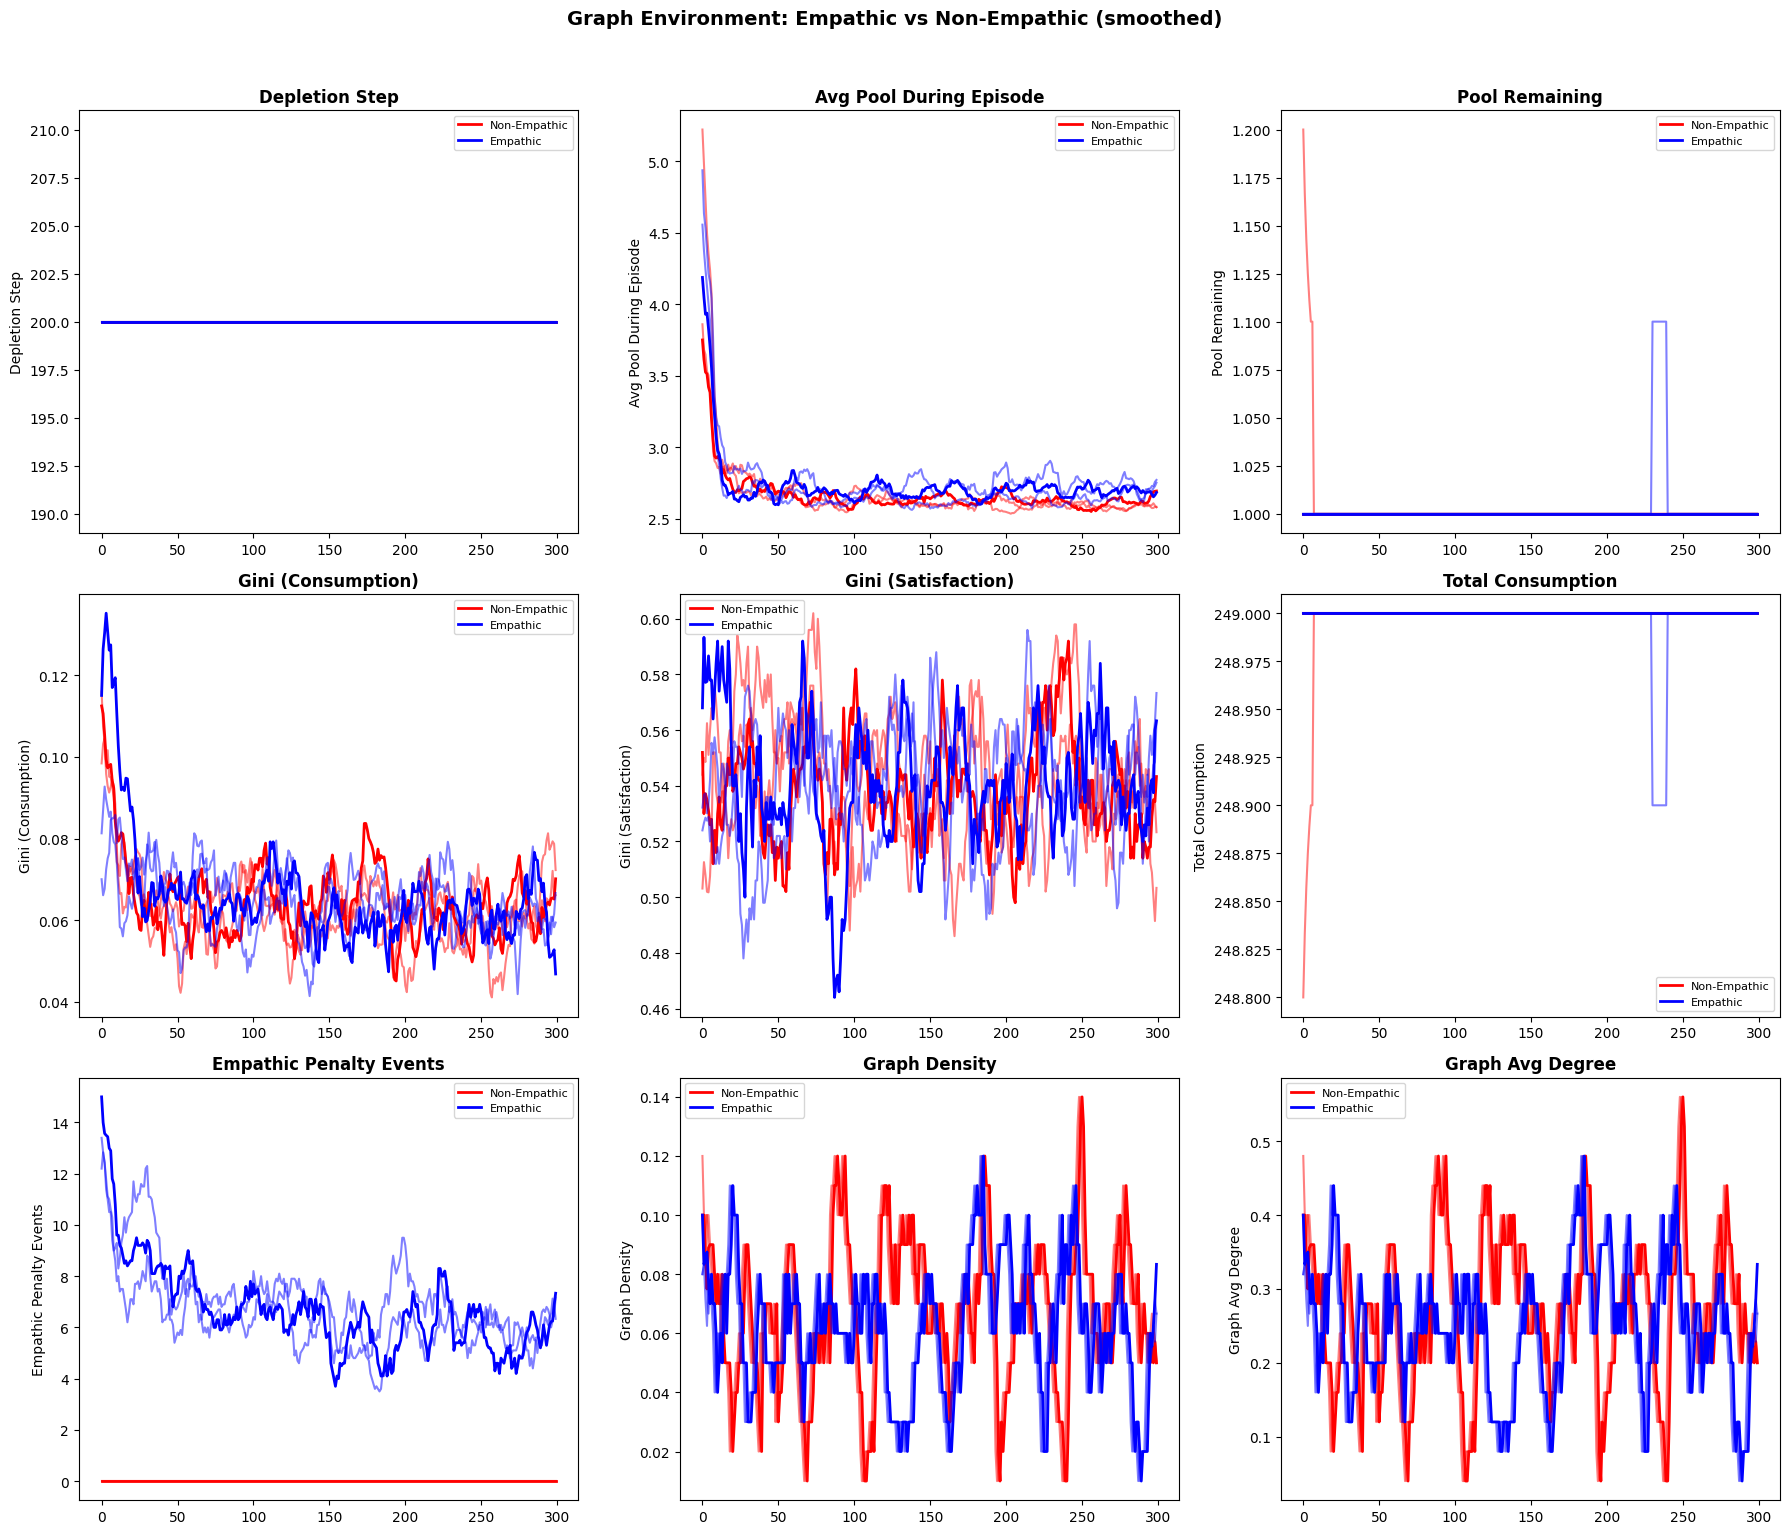

In [6]:
def smooth(data, window=10):
    """Apply centered moving average smoothing."""
    return data.rolling(window=window, min_periods=1, center=True).mean()


if len(df) > 0 and len(df['alpha'].unique()) >= 2:
    fig, axes = plt.subplots(3, 3, figsize=(18, 15))
    window = 10
    colors = {0.0: 'red', 0.5: 'blue'}
    labels = {0.0: 'Non-Empathic', 0.5: 'Empathic'}
    
    plot_metrics = [
        ('depletion_step', 'Depletion Step'),
        ('avg_pool_during_episode', 'Avg Pool During Episode'),
        ('pool_remaining', 'Pool Remaining'),
        ('gini_consumption', 'Gini (Consumption)'),
        ('gini_satisfaction', 'Gini (Satisfaction)'),
        ('total_consumption', 'Total Consumption'),
        ('empathic_penalties_count', 'Empathic Penalty Events'),
        ('graph_density', 'Graph Density'),
        ('graph_avg_degree', 'Graph Avg Degree'),
    ]
    if 'mean_reward' in df.columns:
        plot_metrics.append(('mean_reward', 'Mean Reward'))
    
    for alpha in sorted(df['alpha'].unique()):
        alpha_data = df[df['alpha'] == alpha]
        color = colors.get(alpha, 'green')
        base_label = labels.get(alpha, f'Alpha={alpha}')
        simulations = sorted(alpha_data['simulation_number'].unique())
        
        for sim_num in simulations:
            sim_data = alpha_data[alpha_data['simulation_number'] == sim_num].sort_values('episode')
            episodes = sim_data['episode']
            alpha_transparency = 1.0 if sim_num == simulations[0] else 0.5
            linewidth = 2 if sim_num == simulations[0] else 1.5
            label = base_label if sim_num == simulations[0] else None
            
            for idx, (col, title) in enumerate(plot_metrics[:9]):
                if col not in sim_data.columns:
                    continue
                r, c = idx // 3, idx % 3
                axes[r, c].plot(episodes, smooth(sim_data[col], window), color=color, linewidth=linewidth, alpha=alpha_transparency, label=label)
                axes[r, c].set_title(title, fontweight='bold')
                axes[r, c].set_ylabel(title)
                axes[r, c].legend(loc='best', fontsize=8)
    
    plt.suptitle('Graph Environment: Empathic vs Non-Empathic (smoothed)', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

## Statistical Comparison (Last N Episodes)

In [7]:
last_n = 20

if len(df) > 0 and len(df['alpha'].unique()) >= 2:
    max_episode = df['episode'].max()
    last_episodes = df[df['episode'] > max_episode - last_n]
    ne_data = last_episodes[last_episodes['alpha'] == 0.0]
    e_data = last_episodes[last_episodes['alpha'] > 0]
    
    print(f"{'='*60}")
    print(f"STATISTICAL COMPARISON (Last {last_n} Episodes)")
    print(f"{'='*60}")
    
    def compare_metric(name, col):
        if col not in df.columns:
            return
        ne_vals = ne_data[col].dropna()
        e_vals = e_data[col].dropna()
        if len(ne_vals) == 0 or len(e_vals) == 0:
            print(f"\n{name}: Insufficient data")
            return
        ne_mean, ne_std = ne_vals.mean(), ne_vals.std()
        e_mean, e_std = e_vals.mean(), e_vals.std()
        try:
            stat, p_value = stats.mannwhitneyu(ne_vals, e_vals, alternative='two-sided')
            sig = "*" if p_value < 0.05 else ""
            if p_value < 0.01: sig = "**"
            if p_value < 0.001: sig = "***"
        except Exception:
            p_value = 1.0
            sig = ""
        pct_change = (e_mean - ne_mean) / (abs(ne_mean) + 1e-6) * 100
        print(f"\n{name}:")
        print(f"  Non-Empathic: {ne_mean:.3f} +/- {ne_std:.3f}")
        print(f"  Empathic:     {e_mean:.3f} +/- {e_std:.3f}")
        print(f"  Difference:   {e_mean - ne_mean:+.3f} ({pct_change:+.1f}%)")
        print(f"  p-value:      {p_value:.4f} {sig}")
    
    metrics = [
        ('Depletion Step', 'depletion_step'),
        ('Pool Remaining', 'pool_remaining'),
        ('Avg Pool During Episode', 'avg_pool_during_episode'),
        ('Total Consumption', 'total_consumption'),
        ('Gini (Consumption)', 'gini_consumption'),
        ('Gini (Satisfaction)', 'gini_satisfaction'),
        ('Graph Density', 'graph_density'),
        ('Graph Avg Degree', 'graph_avg_degree'),
        ('Empathic Penalty Events', 'empathic_penalties_count'),
    ]
    if 'mean_reward' in df.columns:
        metrics.append(('Mean Reward', 'mean_reward'))
    for name, col in metrics:
        compare_metric(name, col)

STATISTICAL COMPARISON (Last 20 Episodes)

Depletion Step:
  Non-Empathic: 200.000 +/- 0.000
  Empathic:     200.000 +/- 0.000
  Difference:   +0.000 (+0.0%)
  p-value:      1.0000 

Pool Remaining:
  Non-Empathic: 1.000 +/- 0.000
  Empathic:     1.000 +/- 0.000
  Difference:   +0.000 (+0.0%)
  p-value:      1.0000 

Avg Pool During Episode:
  Non-Empathic: 2.605 +/- 0.078
  Empathic:     2.707 +/- 0.148
  Difference:   +0.102 (+3.9%)
  p-value:      0.0000 ***

Total Consumption:
  Non-Empathic: 249.000 +/- 0.000
  Empathic:     249.000 +/- 0.000
  Difference:   +0.000 (+0.0%)
  p-value:      1.0000 

Gini (Consumption):
  Non-Empathic: 0.063 +/- 0.024
  Empathic:     0.063 +/- 0.024
  Difference:   +0.001 (+0.9%)
  p-value:      0.6996 

Gini (Satisfaction):
  Non-Empathic: 0.533 +/- 0.068
  Empathic:     0.546 +/- 0.068
  Difference:   +0.013 (+2.4%)
  p-value:      0.2914 

Graph Density:
  Non-Empathic: 0.065 +/- 0.073
  Empathic:     0.040 +/- 0.067
  Difference:   -0.025 (-38.5%

## Learning Curves (Mean Reward)

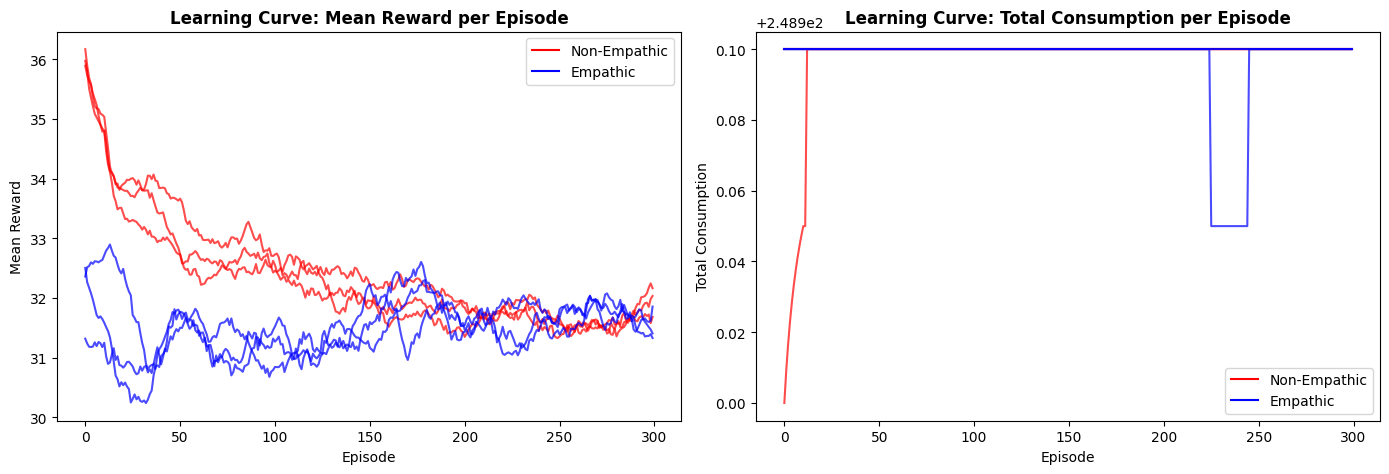

In [8]:
if len(df) > 0 and 'mean_reward' in df.columns:
    reward_cols = [c for c in df.columns if c.startswith('total_reward_')]
    if reward_cols:
        df['mean_reward'] = df[reward_cols].mean(axis=1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    window = 20
    colors = {0.0: 'red', 0.5: 'blue'}
    for alpha in sorted(df['alpha'].unique()):
        alpha_data = df[df['alpha'] == alpha]
        for sim_num in sorted(alpha_data['simulation_number'].unique()):
            sim_data = alpha_data[alpha_data['simulation_number'] == sim_num].sort_values('episode')
            episodes = sim_data['episode']
            axes[0].plot(episodes, smooth(sim_data['mean_reward'], window), color=colors.get(alpha, 'green'), alpha=0.7)
        axes[0].plot([], [], color=colors.get(alpha, 'green'), label='Empathic' if alpha > 0 else 'Non-Empathic')
    axes[0].legend()
    axes[0].set_ylabel('Mean Reward')
    axes[0].set_title('Learning Curve: Mean Reward per Episode', fontweight='bold')
    axes[0].set_xlabel('Episode')
    
    # Total consumption over episodes
    for alpha in sorted(df['alpha'].unique()):
        alpha_data = df[df['alpha'] == alpha]
        for sim_num in sorted(alpha_data['simulation_number'].unique()):
            sim_data = alpha_data[alpha_data['simulation_number'] == sim_num].sort_values('episode')
            axes[1].plot(sim_data['episode'], smooth(sim_data['total_consumption'], window), color=colors.get(alpha, 'green'), alpha=0.7)
        axes[1].plot([], [], color=colors.get(alpha, 'green'), label='Empathic' if alpha > 0 else 'Non-Empathic')
    axes[1].legend()
    axes[1].set_ylabel('Total Consumption')
    axes[1].set_title('Learning Curve: Total Consumption per Episode', fontweight='bold')
    axes[1].set_xlabel('Episode')
    plt.tight_layout()
    plt.show()

## Distribution Analysis (Final Episodes)

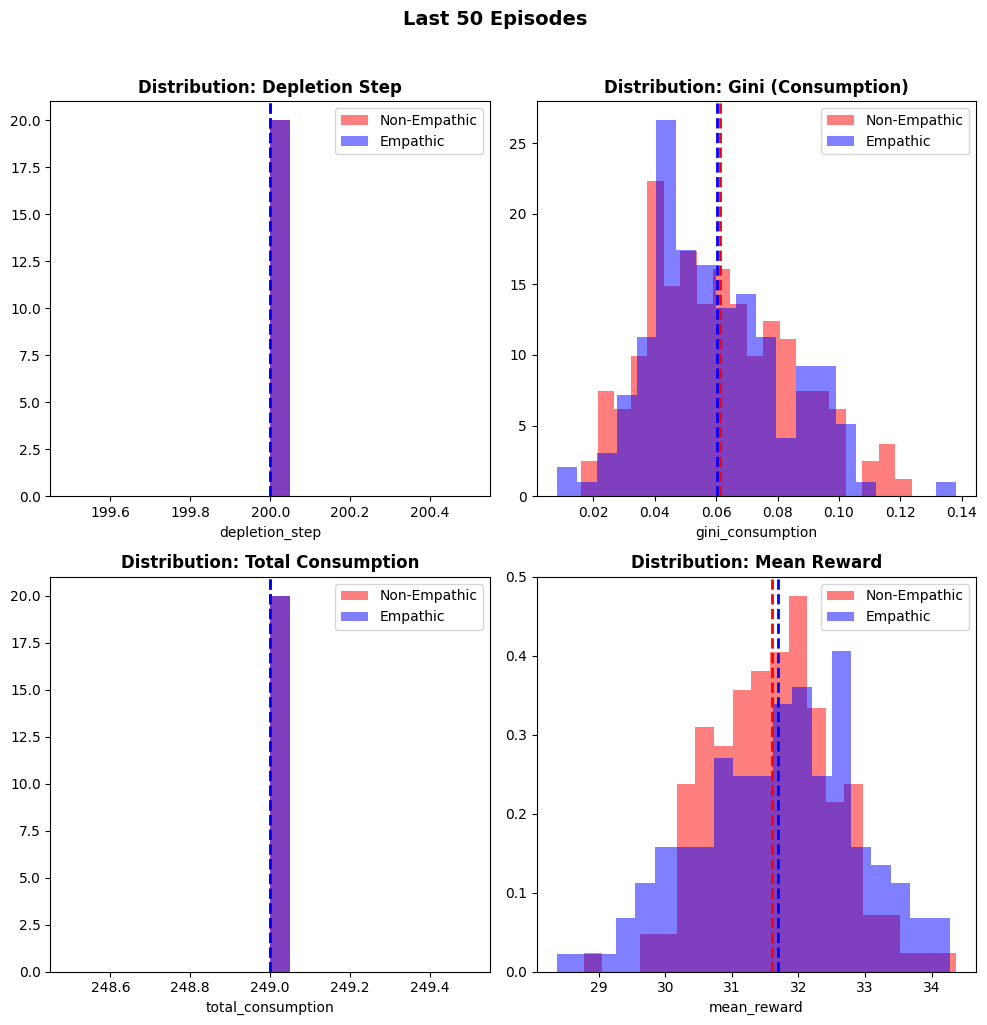

In [9]:
last_n = 50

if len(df) > 0 and len(df['alpha'].unique()) >= 2:
    max_episode = df['episode'].max()
    last_episodes = df[df['episode'] > max_episode - last_n]
    ne_data = last_episodes[last_episodes['alpha'] == 0.0]
    e_data = last_episodes[last_episodes['alpha'] > 0]
    
    dist_metrics = [
        ('depletion_step', 'Depletion Step'),
        ('gini_consumption', 'Gini (Consumption)'),
        ('total_consumption', 'Total Consumption'),
        ('mean_reward', 'Mean Reward'),
    ]
    dist_metrics = [(c, t) for c, t in dist_metrics if c in df.columns]
    n_plots = len(dist_metrics)
    fig, axes = plt.subplots(2, (n_plots + 1) // 2, figsize=(5 * ((n_plots + 1) // 2), 5 * 2))
    axes = np.atleast_1d(axes).flatten()
    for idx, (col, title) in enumerate(dist_metrics):
        ax = axes[idx]
        ax.hist(ne_data[col].dropna(), bins=20, alpha=0.5, color='red', label='Non-Empathic', density=True)
        ax.hist(e_data[col].dropna(), bins=20, alpha=0.5, color='blue', label='Empathic', density=True)
        ax.axvline(ne_data[col].mean(), color='red', linestyle='--', linewidth=2)
        ax.axvline(e_data[col].mean(), color='blue', linestyle='--', linewidth=2)
        ax.set_xlabel(col)
        ax.set_title(f'Distribution: {title}', fontweight='bold')
        ax.legend()
    for j in range(len(dist_metrics), len(axes)):
        axes[j].set_visible(False)
    plt.suptitle(f'Last {last_n} Episodes', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

## Per-Agent Analysis (Last N Episodes)

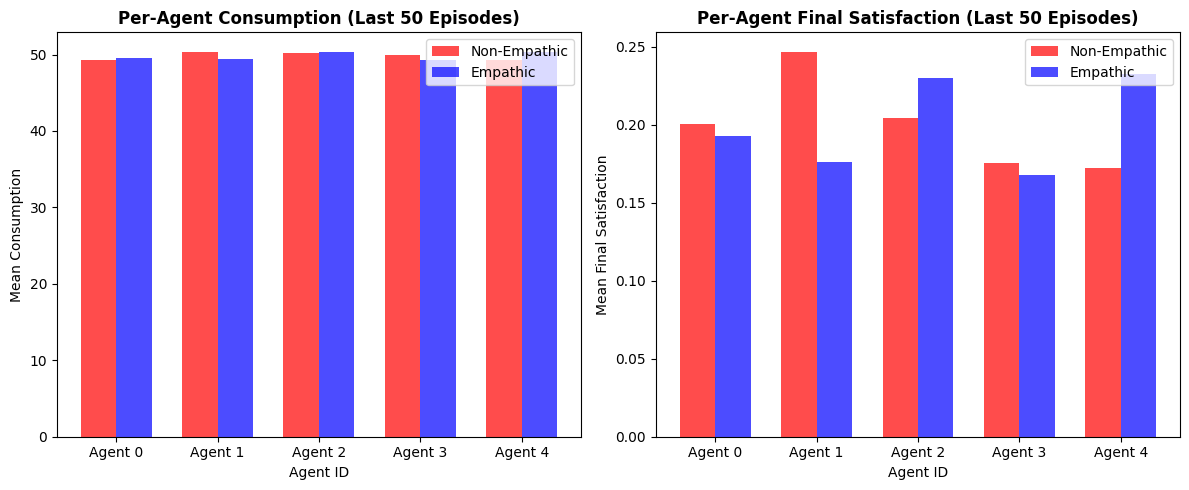

In [10]:
last_n = 50

if len(df) > 0:
    max_episode = df['episode'].max()
    last_episodes = df[df['episode'] > max_episode - last_n]
    
    consumption_cols = [c for c in df.columns if c.startswith('consumption_per_agent_')]
    satisfaction_cols = [c for c in df.columns if c.startswith('final_satisfaction_')]
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    if consumption_cols:
        ne_consumption = last_episodes[last_episodes['alpha'] == 0.0][consumption_cols].mean()
        e_consumption = last_episodes[last_episodes['alpha'] > 0][consumption_cols].mean()
        x = np.arange(len(consumption_cols))
        width = 0.35
        axes[0].bar(x - width/2, ne_consumption.values, width, label='Non-Empathic', color='red', alpha=0.7)
        axes[0].bar(x + width/2, e_consumption.values, width, label='Empathic', color='blue', alpha=0.7)
        axes[0].set_xticks(x)
        axes[0].set_xticklabels([f'Agent {i}' for i in range(len(consumption_cols))])
        axes[0].set_xlabel('Agent ID')
        axes[0].set_ylabel('Mean Consumption')
        axes[0].set_title('Per-Agent Consumption (Last 50 Episodes)', fontweight='bold')
        axes[0].legend()
    
    if satisfaction_cols:
        ne_satisfaction = last_episodes[last_episodes['alpha'] == 0.0][satisfaction_cols].mean()
        e_satisfaction = last_episodes[last_episodes['alpha'] > 0][satisfaction_cols].mean()
        x = np.arange(len(satisfaction_cols))
        width = 0.35
        axes[1].bar(x - width/2, ne_satisfaction.values, width, label='Non-Empathic', color='red', alpha=0.7)
        axes[1].bar(x + width/2, e_satisfaction.values, width, label='Empathic', color='blue', alpha=0.7)
        axes[1].set_xticks(x)
        axes[1].set_xticklabels([f'Agent {i}' for i in range(len(satisfaction_cols))])
        axes[1].set_xlabel('Agent ID')
        axes[1].set_ylabel('Mean Final Satisfaction')
        axes[1].set_title('Per-Agent Final Satisfaction (Last 50 Episodes)', fontweight='bold')
        axes[1].legend()
    
    plt.tight_layout()
    plt.show()